## Problema
Buscamos clasificar la variable target binaria 'Arrest', que define si un delito terminó en arresto o no.

Utilizamos el dataset después de pasar por el preprocesamiento (`2_preprocesamiento.ipynb`) y utilizamos la información de los otros notebooks para terminar de preparar el dataset.

Para el train/test split realizamos un split estratificado para mantener la proporción de la variable target. Las transformaciones se ajustan para train pero se aplican a train y test. Esto se hace para evitar data leakage.

El balanceo se va a aplicar SOLO a train para que test conserve la proporción real de arrestos y que se asemeje lo más posible a la realidad.

In [41]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, TargetEncoder, MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA

In [42]:
# Usamos dataset como lo dejamos en preprocesamiento
df = pd.read_pickle('chicago_2015_limpio.pkl')
print(f"{df.shape[0]:,} filas × {df.shape[1]} columnas")
df.head()

264,882 filas × 17 columnas


,Block,Primary Type,Description,Location Description,Arrest,Domestic,Beat,Ward,Community Area,X Coordinate,Y Coordinate,Month,Day,Hour,Weekday,hora_default,fecha_default
0,075XX S EMERALD AVE,CRIMINAL DAMAGE,TO VEHICLE,STREET,False,False,621,17.0,68.0,1172605.0,1854931.0,12,31,23,3,False,False
1,015XX N KEDZIE AVE,THEFT,FROM BUILDING,RESIDENCE PORCH HALLWAY,False,False,1422,26.0,23.0,NaN,NaN,12,31,23,3,False,False
2,079XX S STONY ISLAND AVE,BATTERY,AGGRAVATED: OTHER DANG WEAPON,STREET,False,False,411,8.0,45.0,1188223.0,1852840.0,12,31,23,3,False,False
3,024XX W FARGO AVE,THEFT,$500 AND UNDER,APARTMENT,False,False,2411,50.0,2.0,1158878.0,1949369.0,12,31,23,3,False,False
4,037XX N CLARK ST,BATTERY,SIMPLE,SIDEWALK,True,False,1923,44.0,6.0,1167786.0,1925033.0,12,31,23,3,False,False


In [43]:
y = df['Arrest'].astype(int)
# Label encoding de la variable binaria target: 0 False, 1 True
X = df.drop(columns=['Arrest'])

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)
X_train, X_test = X_train.copy(), X_test.copy()

# Mantenemos proporción de arrestos en train y test
print(f"Train: {len(X_train):,} filas | Test: {len(X_test):,} filas")
pd.DataFrame({
    'total': y.value_counts(normalize=True),
    'train': y_train.value_counts(normalize=True),
    'test': y_test.value_counts(normalize=True),
}).rename(index={0: 'Sin arresto', 1: 'Con arresto'}).round(4)

Train: 211,905 filas | Test: 52,977 filas


,total,train,test
Arrest,,,
Sin arresto,0.7355,0.7355,0.7355
Con arresto,0.2645,0.2645,0.2645


## Valores faltantes
Quedan nulos en las variables de locación como 'Ward', 'Community Area' y las coordenadas.
Dado que 'Beat' no presenta nulos y es la zona más chica, lo usamos para imputar valores.
En el caso de las coordenadas utilizamos la media de cada 'Beat'
En el caso de 'Ward' y 'Community Area' usamos la moda porque son categóricas.

Se calculan los valores usando el dataset de train pero se aplican a ambos train y test. En caso de haber un 'Beat' faltante en train que aparece en test, se usa el valor global.

Dado que la data faltante tiene una razón (protección de la identidad de la víctima) y es información relevante, vamos a crear la variable "coord_faltante" para no perder el dato de qué delitos tienen coordinadas faltantes.

In [44]:
for X_ in (X_train, X_test):
    # ya sabemos por eda que los faltantes en las coordinadas son los mismos faltantes que
    # Ward y Community Area
    X_['coord_faltante'] = X_['X Coordinate'].isna()

medias = X_train.groupby('Beat')[['X Coordinate', 'Y Coordinate']].mean()
modas = X_train.groupby('Beat')[['Ward', 'Community Area']].agg(lambda s: s.mode().iloc[0])

# Para casos donde haya un Beat en test que no se encuentre en train
global_media = X_train[['X Coordinate', 'Y Coordinate']].mean()
global_moda = X_train[['Ward', 'Community Area']].mode().iloc[0]

# transform: se aplican igual a train y a test
for X_ in (X_train, X_test):
    for col in ['X Coordinate', 'Y Coordinate']:
        X_[col] = X_[col].fillna(X_['Beat'].map(medias[col])).fillna(global_media[col])
    for col in ['Ward', 'Community Area']:
        X_[col] = X_[col].fillna(X_['Beat'].map(modas[col])).fillna(global_moda[col])

print("Nulos en train:", X_train.isna().sum().sum())
print("Nulos en test:", X_test.isna().sum().sum())

Nulos en train: 0
Nulos en test: 0


# Feature Engineering
Para las variables cíclicas (hora, mes, día, etc) hay que coodificarlas de forma que mantengan esta ciclicidad (ej: 23 debe estar al lado de 0, no ser extremos opuestos) ==> usamos cyclic encoding con seno y coseno.

En el notebook de preprocesamiento también se vio que la combinación de 'Primary Type' + 'Description' son las más asociadas al target (`V(Arrest) = 0.733`), más que 'Primary Type' sola por su cuenta. Puede ser útil entonces crearla como feature.

Ward y Community Area se vuelven redundantes con Beat y Block (`V = 0.71–0.98`)

In [45]:
def cyclic_encoding(X_):
    for col, periodo in [('Hour', 24), ('Month', 12), ('Weekday', 7)]:
        X_[f'{col}_sin'] = np.sin(2 * np.pi * X_[col] / periodo)
        X_[f'{col}_cos'] = np.cos(2 * np.pi * X_[col] / periodo)
    dias_mes = pd.to_datetime(dict(year=2015, month=X_['Month'], day=1)).dt.days_in_month
    X_['Day_sin'] = np.sin(2 * np.pi * (X_['Day'] - 1) / dias_mes)
    X_['Day_cos'] = np.cos(2 * np.pi * (X_['Day'] - 1) / dias_mes)
    return X_

def add_remove_features(X_):
    X_ = cyclic_encoding(X_)
    X_['Tipo_Desc'] = X_['Primary Type'] + ' | ' + X_['Description']
    return X_.drop(columns=['Hour', 'Month', 'Weekday', 'Day', 'Description', 'Ward', 'Community Area'])

X_train = add_remove_features(X_train)
X_test = add_remove_features(X_test)

X_train.columns.tolist()

['Block',
 'Primary Type',
 'Location Description',
 'Domestic',
 'Beat',
 'X Coordinate',
 'Y Coordinate',
 'hora_default',
 'fecha_default',
 'coord_faltante',
 'Hour_sin',
 'Hour_cos',
 'Month_sin',
 'Month_cos',
 'Weekday_sin',
 'Weekday_cos',
 'Day_sin',
 'Day_cos',
 'Tipo_Desc']

## Codificación
Contamos mayoritariamente con variables categóricas. Se tiene en cuenta su cardinalidad (se puede ver en el archivo de EDA) a la hora de codificarlas.

| Variable | # Categorías | Técnica | Razón |
|---|---|---|---|
| `Primary Type` | 31 | One-hot | Cardinalidad baja y sin orden |
| `Location Description` | 116 | One-hot con agrupación de específicas | Las categorías con menos de 0.5% de los registros se agrupan en una sola para evitar muchas columnas casi vacías |
| `Tipo_Desc` | 366 | Target encoding | Cardinalidad alta, mucha relación con variable target |
| `Beat` | 274 | Target encoding | Cardinalidad alta |
| `Block` | ~27000 | Target encoding | Cardinalidad extrema |
| `Domestic` | 2 | Binaria | Booleana, 0 => False, 1 => True |


Target encoding reemplaza cada categoría por la tasa de arresto de esa categoría según el train set. Es la opción más informativa, compacta y efectiva para casos de alta cardinalidad. Corre el riesgo de overfitting.

In [46]:
oh_encoder = OneHotEncoder(min_frequency=0.005, handle_unknown='infrequent_if_exist', sparse_output=False)
cols_oh = ['Primary Type', 'Location Description']
oh_train = pd.DataFrame(oh_encoder.fit_transform(X_train[cols_oh]), index=X_train.index,
                         columns=oh_encoder.get_feature_names_out(cols_oh))
oh_test = pd.DataFrame(oh_encoder.transform(X_test[cols_oh]), index=X_test.index,
                        columns=oh_encoder.get_feature_names_out(cols_oh))

target_encoder = TargetEncoder(target_type='binary', cv=5, random_state=42)
cols_target = ['Tipo_Desc', 'Beat', 'Block']
target_train = pd.DataFrame(target_encoder.fit_transform(X_train[cols_target].astype(str), y_train), index=X_train.index,
                        columns=[f'{c}_te' for c in cols_target])
target_test = pd.DataFrame(target_encoder.transform(X_test[cols_target].astype(str)), index=X_test.index,
                       columns=[f'{c}_te' for c in cols_target])

# Binarias y numéricas
cols_bin = ['Domestic', 'hora_default', 'fecha_default', 'coord_faltante']
cols_num = ['X Coordinate', 'Y Coordinate'] + [c for c in X_train.columns if c.endswith(('_sin', '_cos'))]

def armar(X_, ohe_, te_):
    return pd.concat([X_[cols_num], X_[cols_bin].astype(int), ohe_, te_], axis=1)

X_train_enc = armar(X_train, oh_train, target_train)
X_test_enc = armar(X_test, oh_test, target_test)

print(f"Columnas después de codificar: {X_train_enc.shape[1]}")
print(f"One-Hot Encoding: {oh_train.shape[1]}")
print(f"Target Encoding: {target_train.shape[1]}")
print(f"Numéricas: {len(cols_num)}")
print(f"Binarias: {len(cols_bin)}")
print(f"Location Description: {X_train['Location Description'].nunique()} categorías ==> "
      f"{sum(c.startswith('Location') for c in oh_train.columns)} columnas one-hoteadas")

Columnas después de codificar: 54
One-Hot Encoding: 37
Target Encoding: 3
Numéricas: 10
Binarias: 4
Location Description: 114 categorías ==> 21 columnas one-hoteadas


/Users/scpicasso/Desktop/UBA/lse_fiuba_analisis_datos_tf/venv/lib/python3.14/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


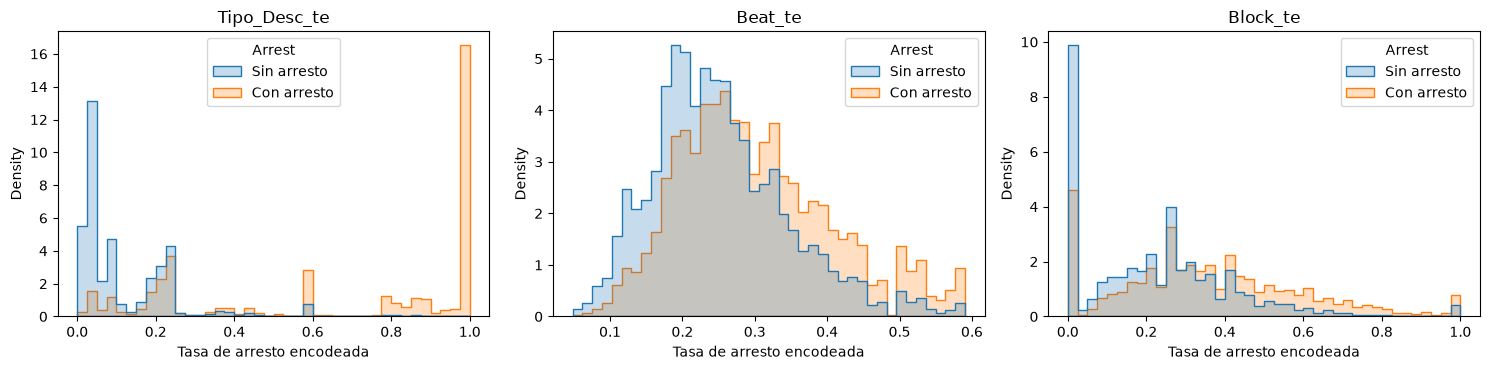

In [47]:
# El target encoding conserva el orden de la asociación con la variable target
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, col in zip(ax, target_train.columns):
    sns.histplot(x=target_train[col], hue=y_train.map({0: 'Sin arresto', 1: 'Con arresto'}),
                 bins=40, stat='density', common_norm=False, element='step', ax=a)
    a.set_title(col)
    a.set_xlabel('Tasa de arresto encodeada')
plt.tight_layout()
plt.show()

# En el caso de Tipo_Desc_te, se hace notoria la separación de Arrest. Los delitos con arresto
# se concentran en valores cercanos a 1 y los sin arresto cerca de 0. Esto se debe a su asociación tan fuerte
# con la variable target

Como se vio en el notebook 3, es conveniente escalar las coordenadas que tienen valores de orden mucho más altos que las otras variables (especialmente ahora que están codificadas). Usamos el MinMaxScaler para que queden también en un rango más acotado [0,1]. Sabemos que las coordenadas no tienen outliers (todas están dentro del rectángulo de la ciudad como se vio en el notebook 1), así que no hace falta estandarizarlas

In [48]:
scaler = MinMaxScaler()
coords = ['X Coordinate', 'Y Coordinate']

# Dado que escalamos con train, puede pasar que en test se salga del rango [0,1]
X_train_enc[coords] = scaler.fit_transform(X_train_enc[coords])
X_test_enc[coords] = scaler.transform(X_test_enc[coords])

rangos = pd.DataFrame({'min_train': X_train_enc.min(), 'max_train': X_train_enc.max(),
                       'min_test': X_test_enc.min(), 'max_test': X_test_enc.max()}).round(3)
rangos.loc[coords + ['Hour_sin', 'Tipo_Desc_te', 'Block_te', 'Domestic']]

,min_train,max_train,min_test,max_test
X Coordinate,0.0,1.0,0.009,1.0
Y Coordinate,0.0,1.0,0.001,1.0
Hour_sin,-1.0,1.0,-1.000,1.0
Tipo_Desc_te,0.0,1.0,0.000,1.0
Block_te,0.0,1.0,0.000,1.0
Domestic,0.0,1.0,0.000,1.0


## Balance
Como ya se planteo antes, hay un ligero desbalance de en la variable target: hay arresto en el 26.5% de los casos. Es un desbalance moderado, pero que puede incentivar al modelo a predecir "Sin Arresto" eligiendo la clase favorecida.

En este caso, al contar con +200 mil filas, se considera que la mejor forma de balancer el dataset de training es usando undersampling. Seguimos manteniendo +100 mil filas sin inventar datos (como en el oversampling). SOLO lo hacemos para training ya que queremos que el dataset de testing refleje la realidad.

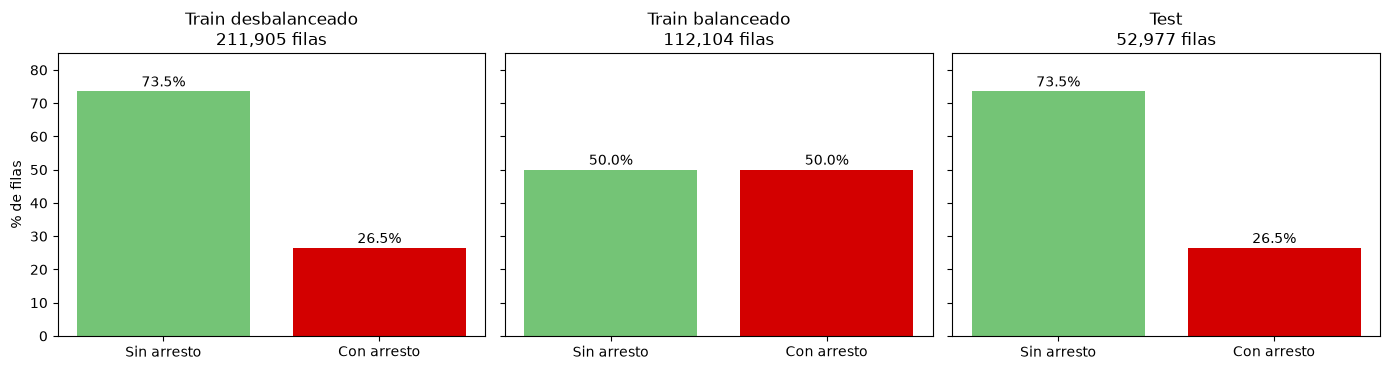

In [49]:
idx_true = y_train[y_train == 1].index
idx_false = y_train[y_train == 0].sample(n=len(idx_true), random_state=42).index
idx_bal = idx_true.union(idx_false)

X_train_bal = X_train_enc.loc[idx_bal]
y_train_bal = y_train.loc[idx_bal]

fig, ax = plt.subplots(1, 3, figsize=(14, 3.8), sharey=True)
for a, (titulo, serie) in zip(ax, [('Train desbalanceado', y_train), ('Train balanceado', y_train_bal),
                                    ('Test', y_test)]):
    p = serie.value_counts(normalize=True).sort_index() * 100
    a.bar(['Sin arresto', 'Con arresto'], p.values, color=['#74C476', '#D30000'])
    for i, v in enumerate(p.values):
        a.text(i, v + 1.5, f"{v:.1f}%", ha='center')
    a.set_title(f"{titulo}\n{len(serie):,} filas")
    a.set_ylim(0, 85)
ax[0].set_ylabel('% de filas')
plt.tight_layout()
plt.show()

# Dimensionalidad
PCA order los features según cuánto contribuyen a la varianza.
Para utilizarlo hay que estandarizar los datos porque es sensible a escala y si no las varaibles con mayor varianza van a dominar.

70% de la varianza: 31 componentes de 54 (57% de las columnas)
80% de la varianza: 36 componentes de 54 (67% de las columnas)
90% de la varianza: 42 componentes de 54 (78% de las columnas)

PC1 explica 5.4%. PC1 + PC2: 9.3%


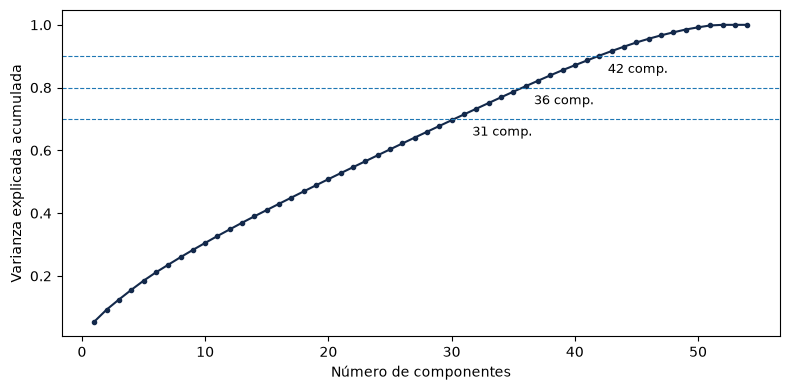

In [50]:
std = StandardScaler()
Z_train = std.fit_transform(X_train_bal)
Z_test = std.transform(X_test_enc)

pca = PCA(random_state=42).fit(Z_train)
var = pca.explained_variance_ratio_
var_acum = var.cumsum()

n_feat = Z_train.shape[1]
umbrales = {u: int(np.argmax(var_acum >= u) + 1) for u in (0.7, 0.8, 0.9)}
for u, n in umbrales.items():
    print(f"{u:.0%} de la varianza: {n} componentes de {n_feat} ({n / n_feat:.0%} de las columnas)")
print(f"\nPC1 explica {var[0]:.1%}. PC1 + PC2: {var_acum[1]:.1%}")

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(range(1, n_feat + 1), var_acum , marker='.', color='#13294B')
for u, n in umbrales.items():
    ax.axhline(u, ls='--', lw=0.8)
    ax.annotate(f"{n} comp.", (n, u), textcoords='offset points', xytext=(6, -12), fontsize=9)
ax.set_xlabel('Número de componentes'); ax.set_ylabel('Varianza explicada acumulada')
plt.tight_layout()
plt.show()

La varianza parece estar bastante repartida. PC1 solo explica el 5,4% y recién con 36 componentes llego a explicar el 80% de la varianza (o sea que de tomar ese umbral, reduciría el 33% de mis columnas).

Ventajas:
Menos columnas significa que puedo acelerar el proceso de entrenamiento
Los componentes no están correlacionados, así que elimino redundancia entre los features

Desventajas:
PCA transforma los features originales y los hace más díficil interpretar
Podemos tener pérdida de información relevante para predecir si hubo arresto o no
La compresión no es lo suficientemente grande: casi todas las features son categóricas en nuestro caso y tienen poca correlacioón lineal entre sí

Conclusión
En nuestro caso, parece que PCA no es lo suficientemente ventajoso como para utilizarlo. 54 columnas no presenta un problema de dimensionalidad tan grande y se logró eliminar mucha de la redundancia gracias al EDA y preprocesamiento previo

Como paso final, se guardan los sets de train y test ya preparados para poder ser utilizados en el modelo

In [51]:
X_train_bal.to_pickle('X_train.pkl'); y_train_bal.to_pickle('y_train.pkl')
X_test_enc.to_pickle('X_test.pkl'); y_test.to_pickle('y_test.pkl')
print(f"Train: {X_train_bal.shape}")
print(f"Test: {X_test_enc.shape}")

Train: (112104, 54)
Test: (52977, 54)
